In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
#from scipy.signal import medfilt, detrend, find_peaks_cwt, medfilt
import glob
import xarray as xr
#from tqdm import tqdm
from matplotlib.colors import PowerNorm, LogNorm, Normalize
from scipy.integrate import cumulative_trapezoid
from sklearn.decomposition import PCA, FastICA, KernelPCA

In [2]:
%matplotlib inline

In [3]:
import os
plot_path = '../../plots/precipitation_cooling'
if not os.path.exists(plot_path):
    os.makedirs(plot_path)

## TOMST

In [4]:
files_tomst = sorted(glob.glob('../../data/TOMST_data/TOMST/TOMST*.csv'))

Processing file: ../../data/TOMST_data/TOMST/TOMST_95228392_2024.08.01_2025.09.01.csv
(9505,)
Processing file: ../../data/TOMST_data/TOMST/TOMST_95228393_2024.08.01_2025.09.01.csv
(9505,)
Processing file: ../../data/TOMST_data/TOMST/TOMST_95228395_2024.08.01_2025.09.01.csv
(9505,)
Processing file: ../../data/TOMST_data/TOMST/TOMST_95228396_2024.08.01_2025.09.01.csv
(9505,)


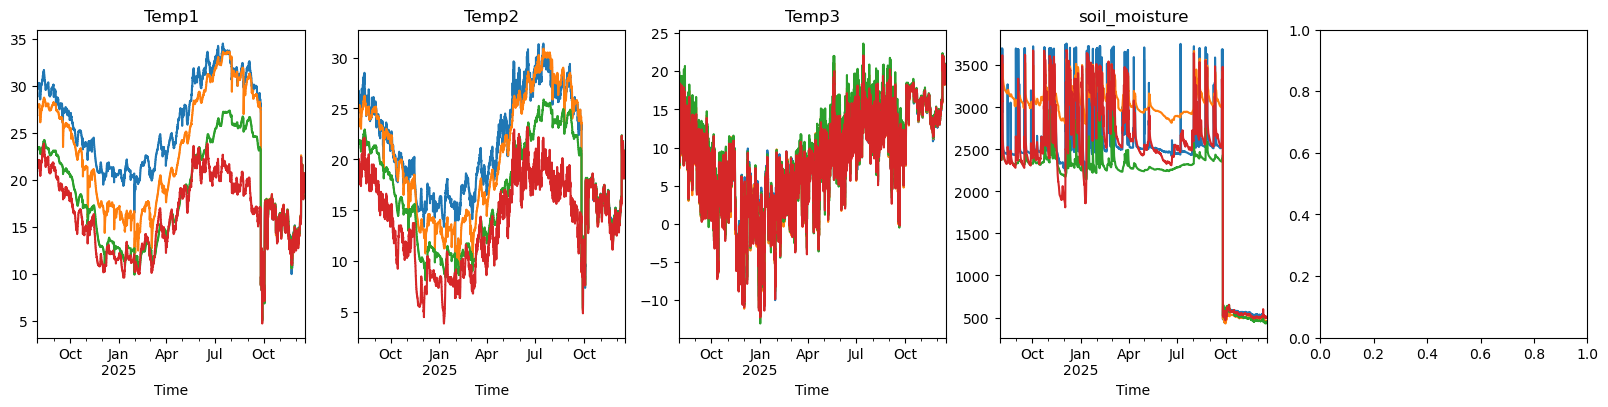

In [5]:
fig, ax = plt.subplots(ncols=5, figsize=(20,4))
all_soil_moisture = []
all_T1 = []

for f, file in enumerate(files_tomst):
    print('Processing file:', file)
    df = pd.read_csv(file, delimiter=';', index_col='Time')

    df.index = pd.to_datetime(df.index, format='%Y-%m-%d %H:%M:%S')
    df.index.name = 'Time'

    head = ['Temp1','Temp2','Temp3', 'soil_moisture']
    for i in range(4):
        df[head[i]].plot(ax=ax[i], c='C%i'%f)
        ax[i].set_title(head[i])


    rng = pd.date_range(start='2024-08-01', end='2025-09-01', freq='1H')
    df = df[~df.index.duplicated()]
    df_resampled = df['soil_moisture'].reindex(rng)
    print(df_resampled.values.shape)
    all_soil_moisture.append(df_resampled.values)
    all_T1.append(df['Temp1'].reindex(rng).values)
    
plt.show()

In [6]:
all_soil_moisture = np.array(all_soil_moisture)
all_T1 = np.array(all_T1)

## Averaging over all the sensors

In [7]:
mean_soil_moisture = -np.nanmean(all_soil_moisture, axis=0)
std_soil_moisture = -np.nanstd(all_soil_moisture, axis=0)
median_soil_moisture = -np.nanmedian(all_soil_moisture, axis=0)


/tmp/ipykernel_400018/876343386.py:1: RuntimeWarning: Mean of empty slice
  mean_soil_moisture = -np.nanmean(all_soil_moisture, axis=0)
/home/geophysic/anaconda3/envs/ghice/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/tmp/ipykernel_400018/876343386.py:3: RuntimeWarning: All-NaN slice encountered
  median_soil_moisture = -np.nanmedian(all_soil_moisture, axis=0)


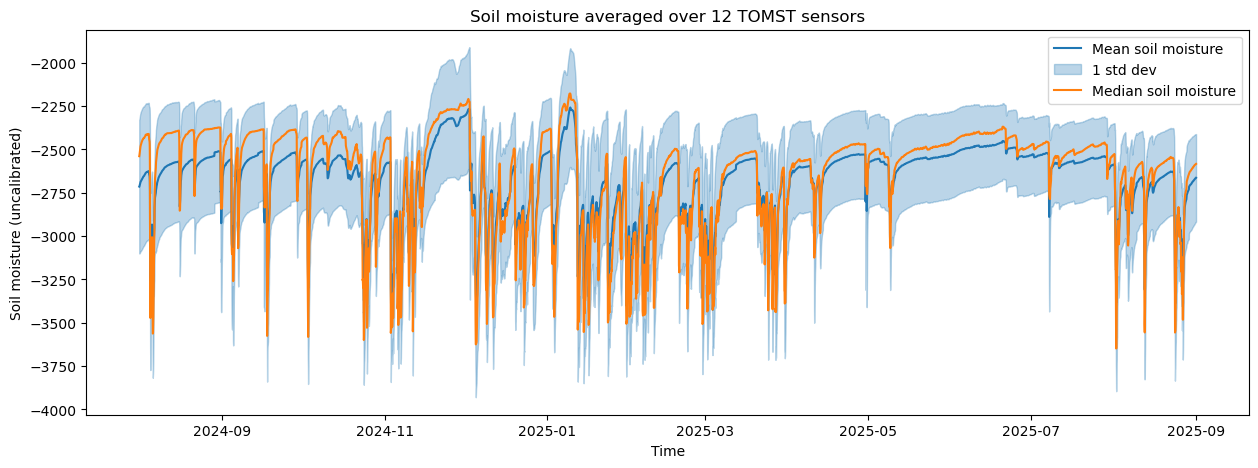

In [8]:
plt.figure(figsize=(15,5))
plt.plot(rng, mean_soil_moisture, label='Mean soil moisture', c='C0')
plt.fill_between(rng, mean_soil_moisture - std_soil_moisture, mean_soil_moisture + std_soil_moisture, color='C0', alpha=0.3, label='1 std dev')
plt.plot(rng, median_soil_moisture, label='Median soil moisture', c='C1')
plt.xlabel('Time')
plt.ylabel('Soil moisture (uncalibrated)')
plt.title('Soil moisture averaged over 12 TOMST sensors')
plt.legend()
plt.show()

## Conversion to volumetric water content %
The polynomial values are the ones given by the TOMST company but it does not reflect accurately the of water content at Gunnuhver : [Find here calibration](https://www.tomst.com/web/wp-content/uploads/2023/05/TMS-calibration-handbook.pdf)

In [9]:
tomst_calib = [-4.41e-8, 3.94e-4, -2.94e-1]

In [10]:
volumetric_soil_moisture = tomst_calib[0] * np.nanmean(all_soil_moisture, axis=0)**2 + tomst_calib[1] * np.nanmean(all_soil_moisture, axis=0) + tomst_calib[2]

/tmp/ipykernel_400018/2957824000.py:1: RuntimeWarning: Mean of empty slice
  volumetric_soil_moisture = tomst_calib[0] * np.nanmean(all_soil_moisture, axis=0)**2 + tomst_calib[1] * np.nanmean(all_soil_moisture, axis=0) + tomst_calib[2]


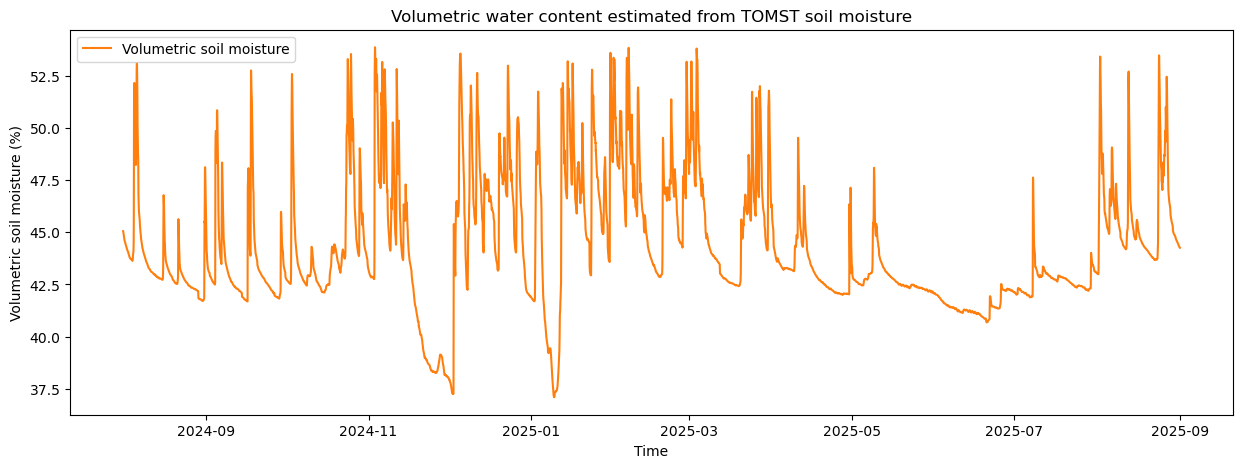

In [11]:
plt.figure(figsize=(15,5))
plt.plot(rng, volumetric_soil_moisture*100, c='C1', label='Volumetric soil moisture')
plt.xlabel('Time')
plt.ylabel('Volumetric soil moisture (%)')
plt.title('Volumetric water content estimated from TOMST soil moisture')
plt.legend()
plt.show()

## Averaging the temperature at level 1

In [12]:
mean_T1 = np.nanmean(all_T1, axis=0)
std_T1 = np.nanstd(all_T1, axis=0)
median_T1 = np.nanmedian(all_T1, axis=0)

/tmp/ipykernel_400018/3663806518.py:1: RuntimeWarning: Mean of empty slice
  mean_T1 = np.nanmean(all_T1, axis=0)
/tmp/ipykernel_400018/3663806518.py:3: RuntimeWarning: All-NaN slice encountered
  median_T1 = np.nanmedian(all_T1, axis=0)


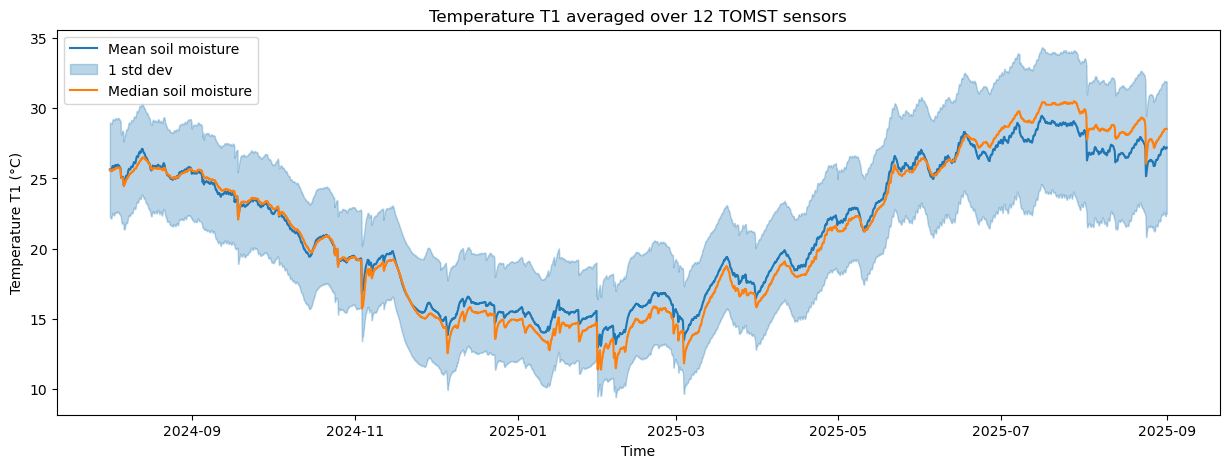

In [13]:
plt.figure(figsize=(15,5))
plt.plot(rng, mean_T1, label='Mean soil moisture', c='C0')
plt.fill_between(rng, mean_T1 - std_T1, mean_T1 + std_T1, color='C0', alpha=0.3, label='1 std dev')
plt.plot(rng, median_T1, label='Median soil moisture', c='C1')
plt.xlabel('Time')
plt.ylabel('Temperature T1 (°C)')
plt.title('Temperature T1 averaged over 12 TOMST sensors')
plt.legend()
plt.show()

## Geothermal features

In [14]:
ds = xr.open_dataset("../../../fbg_data_r/gunnvher_channel_5_fbg_cleaned_10s.nc")

<Figure size 640x480 with 0 Axes>

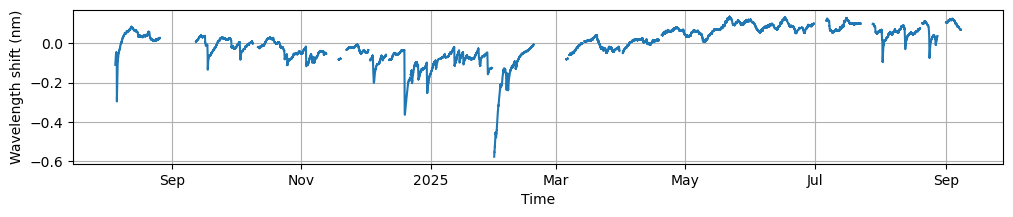

In [15]:
plt.figure()
(ds.Wavelength_nm - ds.Wavelength_nm.mean(dim='Time')).sel(FBG=0).plot(figsize=(12,2))
plt.ylabel('Wavelength shift (nm)')
plt.grid()
plt.show()

In [16]:
data = (ds.Wavelength_nm - ds.Wavelength_nm.mean(dim='Time'))
geo_temp  = data.sel(FBG=0).resample(Time='1H').mean()
geo_temp = geo_temp.dropna('Time')

<string>:6: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.


## Importing data from ERA5 Single level

In [17]:
dw = xr.open_dataset('../../data/weather/t2m_gunnuvher_era5_2024-08-01_to_2025-10-01.nc')

In [18]:
common_time_era5 = np.intersect1d(geo_temp.Time.values, dw.valid_time.values)
dw_ = dw.t2m.sel(valid_time=common_time_era5) - 273.15  # to degC

In [19]:
xl_weather = pd.read_excel('../../data/weather/Vedurgogn_VI_2026-03-23_rviti_31640.xlsx', sheet_name='Veðurathuganir', index_col='time')
xl_weather.index = pd.to_datetime(xl_weather.index)
print(xl_weather)

                     station           name  year  month  day  hour  minute  \
time                                                                          
2024-08-01 00:00:00    31640  Reykjanesviti  2024      7   31    24       0   
2024-08-01 00:10:00    31640  Reykjanesviti  2024      8    1     0      10   
2024-08-01 00:20:00    31640  Reykjanesviti  2024      8    1     0      20   
2024-08-01 00:30:00    31640  Reykjanesviti  2024      8    1     0      30   
2024-08-01 00:40:00    31640  Reykjanesviti  2024      8    1     0      40   
...                      ...            ...   ...    ...  ...   ...     ...   
2025-09-01 23:10:00    31640  Reykjanesviti  2025      9    1    23      10   
2025-09-01 23:20:00    31640  Reykjanesviti  2025      9    1    23      20   
2025-09-01 23:30:00    31640  Reykjanesviti  2025      9    1    23      30   
2025-09-01 23:40:00    31640  Reykjanesviti  2025      9    1    23      40   
2025-09-01 23:50:00    31640  Reykjanesviti  2025   

In [20]:
imo_weather = xr.DataArray(xl_weather['t'], coords={'time': xl_weather.index}, dims=['time'])
imo_rh = xr.DataArray(xl_weather['rh'], coords={'time': xl_weather.index}, dims=['time'])

In [21]:
common_time_imo = np.intersect1d(geo_temp.Time.values, imo_weather.time.values)
imo_weather_ =  imo_weather.sel(time=common_time_imo)

Slope: 11.9897 pm/degC
Slope: 11.0820 pm/degC


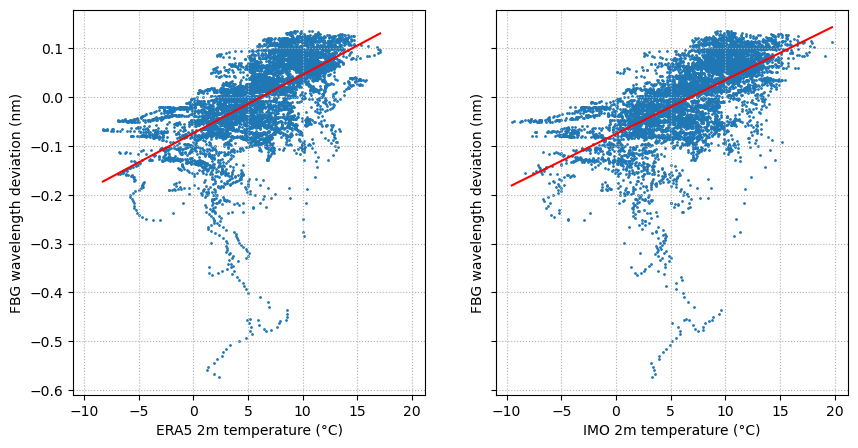

In [22]:
fig, ax = plt.subplots(figsize=(10,5), ncols=2, sharex=True, sharey=True)
scatter = True
bins = 100 
if scatter :
    ax[0].scatter(dw_, geo_temp.sel(Time=common_time_era5), s=1)
    ax[1].scatter(imo_weather_, geo_temp.sel(Time=common_time_imo), s=1)
else :
    ax[0].hist2d(dw_, geo_temp.sel(Time=common_time_era5), bins=bins, cmap='magma')
    ax[1].hist2d(imo_weather_, geo_temp.sel(Time=common_time_imo), bins=bins, cmap='magma')


m_era, p_era = np.polyfit(dw_.values, geo_temp.sel(Time=common_time_era5).values, 1)
x = np.linspace(dw_.min(), dw_.max(), 100)
ax[0].plot(x, m_era*x + p_era, color='r')
print(f'Slope: {m_era*1000:.4f} pm/degC')
ax[0].set_xlabel('ERA5 2m temperature (°C)')
ax[0].set_ylabel('FBG wavelength deviation (nm)')
ax[0].grid(ls=':')


m_imo, p_imo = np.polyfit(imo_weather_.values, geo_temp.sel(Time=common_time_imo).values, 1)
x = np.linspace(imo_weather_.min(), imo_weather_.max(), 100)
ax[1].plot(x, m_imo*x + p_imo, color='r')
print(f'Slope: {m_imo*1000:.4f} pm/degC')
ax[1].set_xlabel('IMO 2m temperature (°C)')
ax[1].set_ylabel('FBG wavelength deviation (nm)')
ax[1].grid(ls=':')

plt.show()

### Removing the wavelength shift caused by air temperature variations

In [23]:
#geo_temp_without_air = geo_temp.sel(Time=common_time_era5).values - (m_era * dw_.values + p_era)
geo_temp_without_air = geo_temp.sel(Time=common_time_imo).values - (m_imo * imo_weather_.values + p_imo)

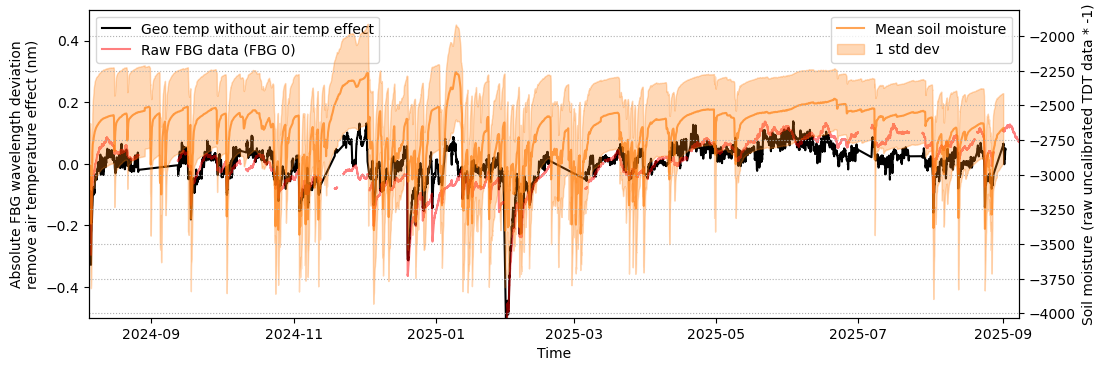

In [24]:
fig, ax = plt.subplots(figsize=(12,4))
ax.plot(geo_temp.sel(Time=common_time_imo).Time.values, (geo_temp_without_air), c='k', zorder=2, label='Geo temp without air temp effect')
ax.plot(data.Time, data.sel(FBG=0), alpha=0.5, color='r',zorder=2, label='Raw FBG data (FBG 0)')
ax.legend(loc='upper left')
ax.set_ylim(-0.5,0.5)
cumtrapz = cumulative_trapezoid(geo_temp_without_air, dx=1, initial=0)

axb=ax.twinx()
axb.plot(rng, mean_soil_moisture, label='Mean soil moisture', c='C1', zorder=1, alpha=0.7)
axb.fill_between(rng, mean_soil_moisture - std_soil_moisture, mean_soil_moisture + std_soil_moisture, color='C1', alpha=0.3, label='1 std dev')
#axb.plot(rng, median_soil_moisture, label='Median soil moisture', c='C1', zorder=1,alpha=0.7)
axb.set_ylabel('Soil moisture (raw uncalibrated TDT data * -1)')
axb.legend(loc='upper right')
ax.set_xlim(geo_temp.Time[0], geo_temp.Time[-1])
ax.set_xlabel('Time')
ax.set_ylabel('Absolute FBG wavelength deviation\nremove air temperature effect (nm)')
plt.grid(ls=':')

plt.show()

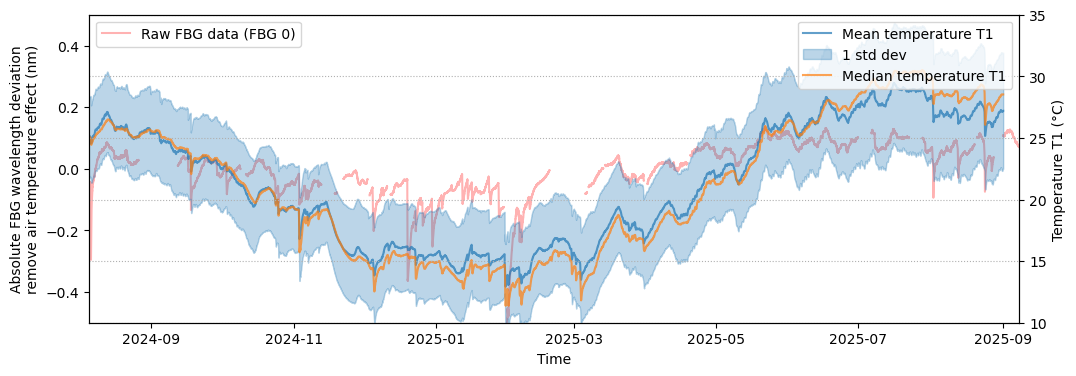

In [25]:
fig, ax = plt.subplots(figsize=(12,4))
ax.plot(data.Time, data.sel(FBG=0), alpha=0.3, color='r',zorder=2, label='Raw FBG data (FBG 0)')
ax.legend(loc='upper left')
ax.set_ylim(-0.5,0.5)

axb=ax.twinx()
axb.plot(rng, mean_T1, label='Mean temperature T1', c='C0', zorder=1, alpha=0.7)
axb.fill_between(rng, mean_T1 - std_T1, mean_T1 + std_T1, color='C0', alpha=0.3, label='1 std dev')
axb.plot(rng, median_T1, label='Median temperature T1', c='C1', zorder=1,alpha=0.7)
axb.set_ylabel('Temperature T1 (°C)')
axb.set_ylim(10,35)
axb.legend(loc='upper right')
ax.set_xlim(geo_temp.Time[0], geo_temp.Time[-1])
ax.set_xlabel('Time')
ax.set_ylabel('Absolute FBG wavelength deviation\nremove air temperature effect (nm)')
plt.grid(ls=':')
plt.show()

In [26]:
ds_without_air = xr.Dataset(
    {'Wavelength_nm_no_air_temp': (('Time'), geo_temp_without_air)},
    coords={
        'Time': geo_temp.sel(Time=common_time_imo).Time
    }
)

ds_mean_soil_moisture = xr.Dataset(
    {'Mean_soil_moisture': (('Time'), mean_soil_moisture)},
    coords={
        'Time': rng
    }
)

In [27]:
ds_without_air = ds_without_air.dropna('Time')

In [28]:
ds_soil_sel = ds_mean_soil_moisture.sel(Time=ds_without_air.Time, method='nearest')

### PCA between soil moisture and FBG temperature

In [29]:
xtrain = np.array([ds_soil_sel.Mean_soil_moisture/np.max(-ds_soil_sel.Mean_soil_moisture.values), ds_without_air.Wavelength_nm_no_air_temp.values/np.max(ds_without_air.Wavelength_nm_no_air_temp.values)]).T

mypca = PCA(n_components=2) #µ composantes principales

res_pca  = mypca.fit(xtrain)

In [30]:
print("Explained variance ratio by component:")
for var_ratio in mypca.explained_variance_ratio_:
    print('%.4E'%var_ratio)

Explained variance ratio by component:
9.9235E-01
7.6523E-03


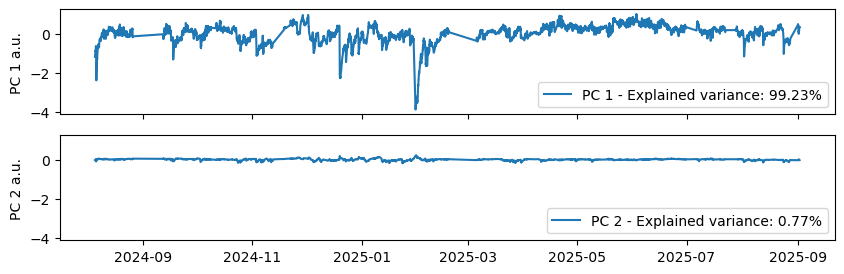

In [31]:
Xnew = mypca.transform(xtrain)

fig, ax = plt.subplots(figsize=(10,3), nrows=len(mypca.explained_variance_ratio_), sharex=True, sharey=True)
for i in range(len(mypca.explained_variance_ratio_)):
    ax[i].plot(ds_without_air.Time, Xnew[:,i], label=f'PC {i+1} - Explained variance: {mypca.explained_variance_ratio_[i]:.2%}')
    ax[i].legend(loc='lower right')
    ax[i].set_ylabel(f'PC {i+1} a.u.')
plt.savefig(f'{plot_path}/PCA_results_tempVSmoisture.png', dpi=300, bbox_inches='tight')
plt.show()

### Relation between soil moisture and FBG temperature

In [32]:
geo_temp_resampled = xr.DataArray(geo_temp_without_air, coords=[geo_temp.sel(Time=common_time_imo).Time], dims=["Time"]).reindex(Time=rng, method='nearest', tolerance=pd.Timedelta('30min'))

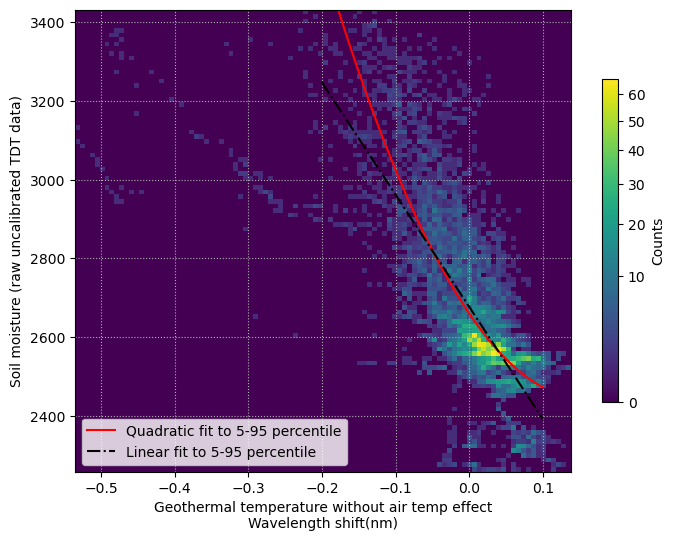

In [33]:
plt.figure(figsize=(8,6))
#plt.hist2d(geo_temp_resampled.values[~np.isnan(geo_temp_resampled.values)], -mean_soil_moisture[~np.isnan(geo_temp_resampled.values)], bins=100)
#plt.scatter(geo_temp_resampled.values, -mean_soil_moisture, s=1, alpha=0.5)

xtrain_raw = geo_temp_resampled.values[~np.isnan(geo_temp_resampled.values)]
xtrain = xtrain_raw[(np.percentile(xtrain_raw, 5) < xtrain_raw) & (xtrain_raw < np.percentile(xtrain_raw, 95))]
ytrain_raw = -mean_soil_moisture[~np.isnan(geo_temp_resampled.values)]
ytrain = ytrain_raw[(np.percentile(xtrain_raw, 5) < xtrain_raw) & (xtrain_raw < np.percentile(xtrain_raw, 95))]

plt.hist2d(xtrain_raw, ytrain_raw, bins=100, norm=PowerNorm(0.5))

m, p = np.polyfit(xtrain,ytrain, 1)
x = np.linspace(-.2, .1, 100)

a,b,c = np.polyfit(xtrain, ytrain, 2)
x_quad = np.linspace(-.2, .1, 100)
plt.plot(x_quad, a*x_quad**2 + b*x_quad + c, color='r', label='Quadratic fit to 5-95 percentile')

plt.plot(x, m*x + p, color='k', ls='-.', label='Linear fit to 5-95 percentile')
plt.xlabel('Geothermal temperature without air temp effect\nWavelength shift(nm)')
plt.ylabel('Soil moisture (raw uncalibrated TDT data)')
plt.colorbar(label='Counts', shrink=0.7)
plt.grid(ls=':')
plt.legend()
plt.show()

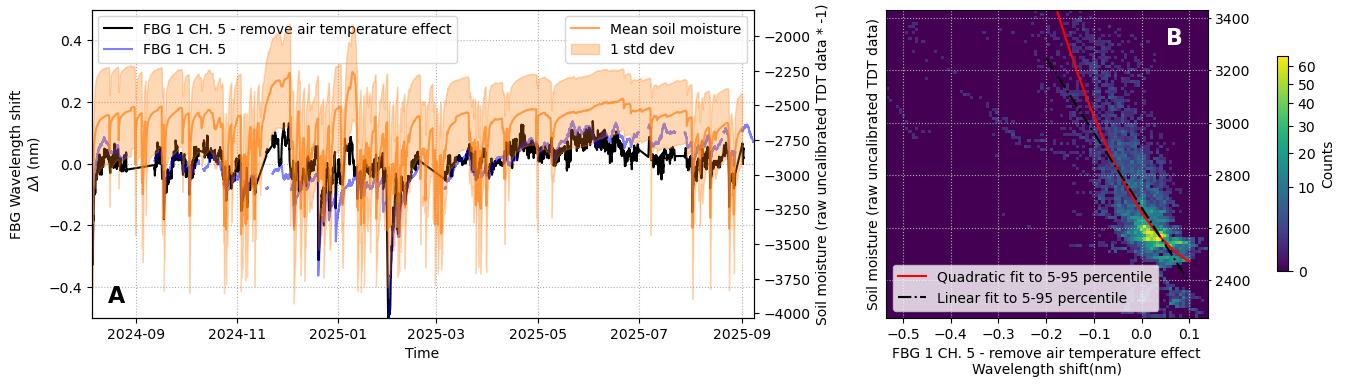

In [34]:
fig = plt.figure(figsize=(18,4))
ax = plt.subplot2grid((1, 10), (0, 0), colspan=6)
ax.plot(geo_temp.sel(Time=common_time_imo).Time.values, (geo_temp_without_air), c='k', zorder=2, label='FBG 1 CH. 5 - remove air temperature effect')
ax.plot(data.Time, data.sel(FBG=0), alpha=0.5, color='b',zorder=2, label='FBG 1 CH. 5')
ax.legend(loc='upper left')
ax.set_ylim(-0.5,0.5)

axb=ax.twinx()
#axt = ax.twinx()
#axt.tick_params(axis='y', left=True, right=False, labelright=False, labelleft=True,length=2)
#axt.set_ylim(-50,50)
#axt.spines['left'].set_position(('outward', 40))
#axt.set_ylabel('$\Delta T$ (°C)')
#axt.plot(geo_temp.sel(Time=common_time_imo).Time.values, (geo_temp_without_air)*1000/10, c='r', zorder=2,)
axb.plot(rng, mean_soil_moisture, label='Mean soil moisture', c='C1', zorder=1, alpha=0.7)
axb.fill_between(rng, mean_soil_moisture - std_soil_moisture, mean_soil_moisture + std_soil_moisture, color='C1', alpha=0.3, label='1 std dev')
#axb.plot(rng, median_soil_moisture, label='Median soil moisture', c='C1', zorder=1,alpha=0.7)
axb.set_ylabel('Soil moisture (raw uncalibrated TDT data * -1)')
axb.legend(loc='upper right')
ax.set_xlim(geo_temp.Time[0], geo_temp.Time[-1])
ax.set_xlabel('Time')
#ax.set_ylabel('Absolute FBG wavelength deviation\nremove air temperature effect (nm)')
ax.set_ylabel('FBG Wavelength shift\n$\Delta \lambda$ (nm)')
ax.grid(ls=':')
ax.text(np.datetime64('2024-08-15'), -.45, 'A', fontsize=16, fontweight='bold')
ax2 = plt.subplot2grid((1, 10), (0, 7), colspan=3)

ax2.hist2d(xtrain_raw, ytrain_raw, bins=100, norm=PowerNorm(0.5))
ax2.plot(x_quad, a*x_quad**2 + b*x_quad + c, color='r', label='Quadratic fit to 5-95 percentile')
ax2.tick_params(axis='y', left=False, right=True, labelright=True, labelleft=False,length=2)
ax2.plot(x, m*x + p, color='k', ls='-.', label='Linear fit to 5-95 percentile')
ax2.set_xlabel('FBG 1 CH. 5 - remove air temperature effect\nWavelength shift(nm)')
ax2.set_ylabel('Soil moisture (raw uncalibrated TDT data)')
fig.colorbar(ax2.collections[0], ax=[ax,ax2], label='Counts', shrink=0.7, pad=.05)
ax2.grid(ls=':')
ax2.legend()
ax2.text(.05, 3300, 'B', fontsize=16, fontweight='bold', c='w')
plt.savefig(plot_path + 'precipitation_cooling.png', dpi=300, bbox_inches='tight')
plt.show()

## Model

### Import the data

In [35]:
era5_precip = xr.open_dataset('/home/geophysic/jgovoort/fbg_gunnuvher/Gunnuvher_paper/era5/gunnvuher_era5_precip.grib')
era5_precip = era5_precip.sel(latitude=63.8236, longitude=-22.6789, method='nearest')
era5_precip_data = era5_precip.tp.values

In [36]:
era5_precip_data = era5_precip_data.reshape(-1) * 1000  # convert from m to mm
time_era5 = era5_precip.valid_time.values.reshape(-1)

ds_era5_precip = xr.Dataset(
    {'ERA5_precip': (('Time'), era5_precip_data)},
    coords={
        'Time': time_era5
    }
)

In [37]:
ds_era5_precip = ds_era5_precip.sel(Time=slice('2024-08-01', '2025-09-01'))

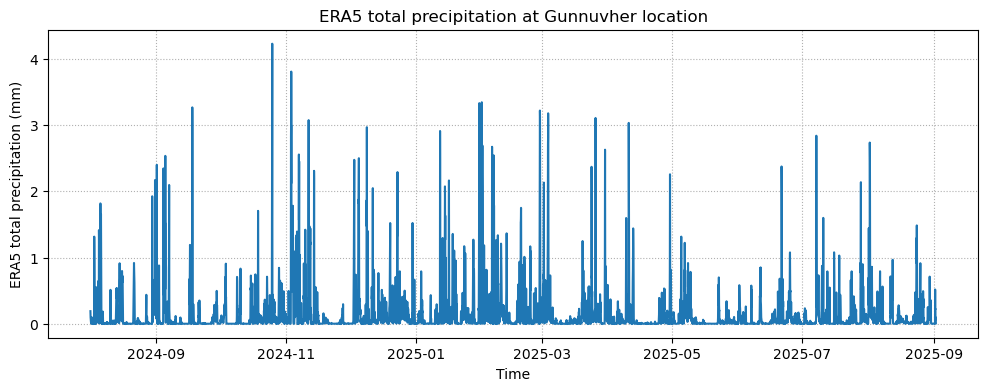

In [38]:
plt.figure(figsize=(12,4))
plt.plot(ds_era5_precip.Time, ds_era5_precip.ERA5_precip)
plt.xlabel('Time')
plt.ylabel('ERA5 total precipitation (mm)')
plt.title('ERA5 total precipitation at Gunnuvher location')
plt.grid(ls=':')
plt.show()

In [39]:
imo_weather_model = imo_weather.resample(time='1min').mean().interpolate_na('time')
#imo_rh_model = imo_rh.resample(time='1min').mean().interpolate_na('time')
#imo_precip_model = np.where(imo_rh_model > 99, 1, 0) * .5 # Simple model: if relative humidity > 95%, assume precipitation of 1 mm/h, else 0. This is a very rough approximation and can be improved with more complex models or actual precipitation data.

In [40]:
dz = .02
steam_vent_depth = 1.5 #m
dt = 1/60 #hour
z = np.arange(0,.5,dz) #m
#tair = np.sin(np.linspace(0, np.pi*(2*np.max(time)/24), len(time))) * 5 + 15
tair = imo_weather_model.values
#time = np.arange(0,1000,dt) #second
time = imo_weather_model.time.values
Temp = np.zeros((len(tair), len(z)))

t_eau = 5 #°C

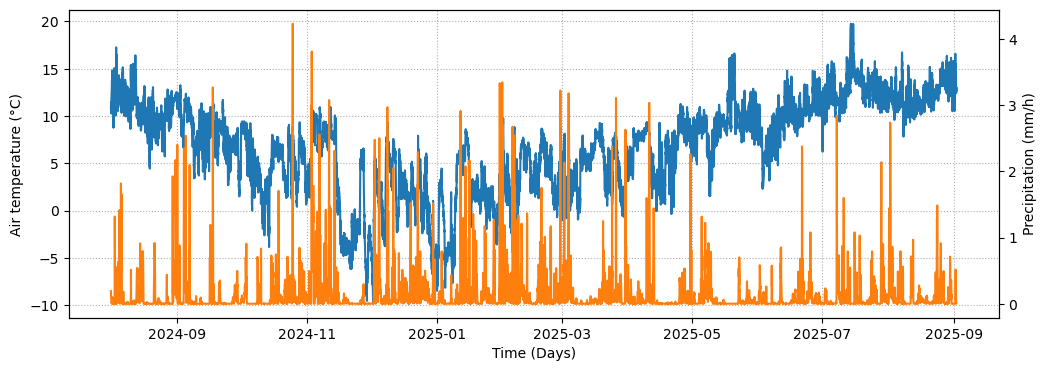

In [41]:

fig, ax = plt.subplots(figsize=(12,4))
ax.plot(time, tair)
ax.set_xlabel('Time (Days)')
ax.set_ylabel('Air temperature (°C)')
axb = ax.twinx()
axb.plot(ds_era5_precip.Time, ds_era5_precip.ERA5_precip, color='C1')
axb.set_ylabel('Precipitation (mm/h)')
ax.grid(ls=':')
plt.show()

In [42]:
ds_era5_precip_model = ds_era5_precip.reindex(Time=imo_weather_model.time.values, method='nearest', tolerance=pd.Timedelta('30min'))
ds_era5_precip_model = ds_era5_precip_model.fillna(0) / 60

In [43]:


#Temp[0,:] = 10*np.exp(-z**2/1**2) # Initial temperature distribution (Gaussian centered at z=0)
#Temp[:,0] = 0
#Temp[:, -1] = 0

Temp[0,:] = np.linspace(20,100, len(z)) # Initial temperature distribution (linear from 120°C at the surface to 20°C at depth)
Temp[:,0] = tair
Temp[:, -1] = 100

#kappa = 8.418e-6 #m^2/s
kappa = 3e-7 * 3600 # https://www.sciencedirect.com/science/article/pii/S1537511016305621#undfig1 *3060 to convert to m^2/hour

#Precipitation = np.zeros_like(time)
#Precipitation[(time > 200) & (time < 300)] = 1
u = (ds_era5_precip_model.ERA5_precip.values/86400)/.2 * 3600 # m/s, convert 1mm/hour to m/s to m/hour by multiplying by 3600, and divide by 0.2 to convert from precipitation to infiltration velocity (assuming 20% infiltration)
#u = np.zeros(time.shape)
#u[10000 : 11000] = .1

r = kappa * dt / dz**2
cfl = np.max(np.abs(u)) * dt / dz

print(r, cfl)
if r > 0.5 :
    print('Warning: r is greater than 0.5, the explicit scheme may be unstable.')
if cfl > 1 :
    print('Warning: CFL number is greater than 1, the explicit scheme may be unstable.')


for i in range(1, len(time)):
    for k in range(1, len(z)-1):
        Temp[i, k] = (kappa*dt/dz**2) * (Temp[i-1, k+1] + Temp[i-1, k-1]) + (1 - 2*(kappa*dt/dz**2)) * Temp[i-1, k]
        if u[i] > 0 and tair[i] < 0: 
            Temp[i, 0] = 0
        Temp[i, k] -= u[i] * (Temp[i-1, k] - Temp[i-1, k-1]) * dt/dz # Advection term

0.045 0.012235509024726017


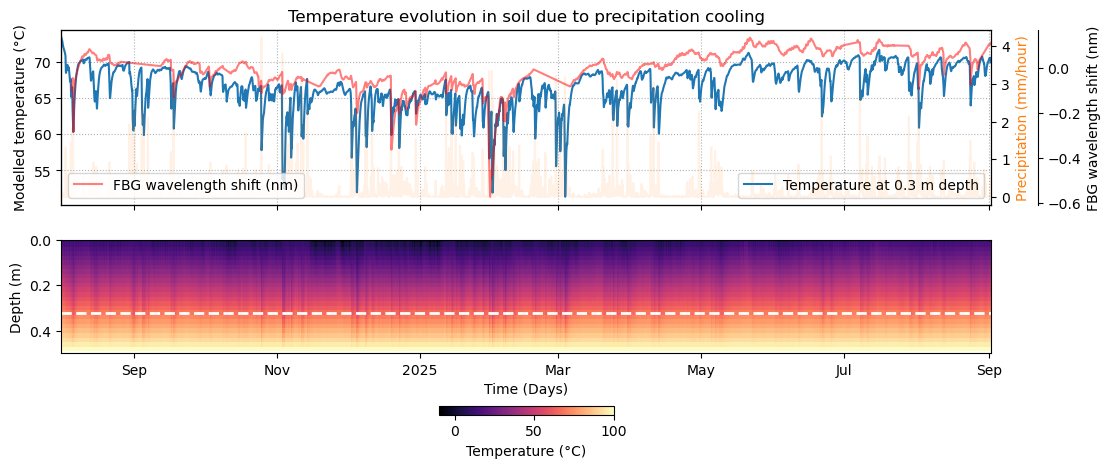

In [44]:
depth = .32

fig, ax = plt.subplots(figsize=(12,5), nrows=2, sharex=True)
ax[1].pcolormesh(time, z, Temp.T, shading='auto', cmap='magma')
#ax[0].set_xlabel('Time (hours)')
ax[1].set_ylabel('Depth (m)')
ax[0].set_title('Temperature evolution in soil due to precipitation cooling')
ax[1].invert_yaxis()
ax[1].set_ylim(.5,0)
fig.colorbar(ax[1].collections[0], label='Temperature (°C)', ax=ax[1], orientation='horizontal', pad=0.3, fraction=0.05)
ax[1].axhline(y=depth, color='white', linestyle='--', linewidth=2)
#fig.colorbar(label='Temperature (°C)', ax=ax[0])
ax[0].plot(time, Temp[:, int(depth/dz)], label='Temperature at %0.1f m depth'%depth)
axb = ax[0].twinx()
axb.plot(ds_era5_precip_model.Time, ds_era5_precip_model.ERA5_precip.values*60, alpha=0.1, label='Precipitation (mm/hour)', color='C1')
axb.set_ylabel('Precipitation (mm/hour)', color='C1')
ax[1].set_xlabel('Time (Days)')
ax[0].set_ylabel('Modelled temperature (°C)')
ax[0].legend()
ax[0].set_xlim(left=time[10])
ax[0].grid(ls=':')
axc = ax[0].twinx()
geo_temp.plot(ax=axc, color='r', alpha=0.5, label='FBG wavelength shift (nm)')
axc.set_ylabel('FBG wavelength shift (nm)')
axc.legend(loc='lower left')
axc.spines['right'].set_position(('axes', 1.05))
plt.show()


/tmp/ipykernel_400018/3826828686.py:49: UserWarning: Converting non-nanosecond precision datetime values to nanosecond precision. This behavior can eventually be relaxed in xarray, as it is an artifact from pandas which is now beginning to support non-nanosecond precision values. This warning is caused by passing non-nanosecond np.datetime64 or np.timedelta64 values to the DataArray or Variable constructor; it can be silenced by converting the values to nanosecond precision ahead of time.
  resampled_geo_temp = geo_temp.reindex(Time=np.arange(geo_temp.Time.values[0], geo_temp.Time.values[-1],1, dtype='datetime64[m]'),


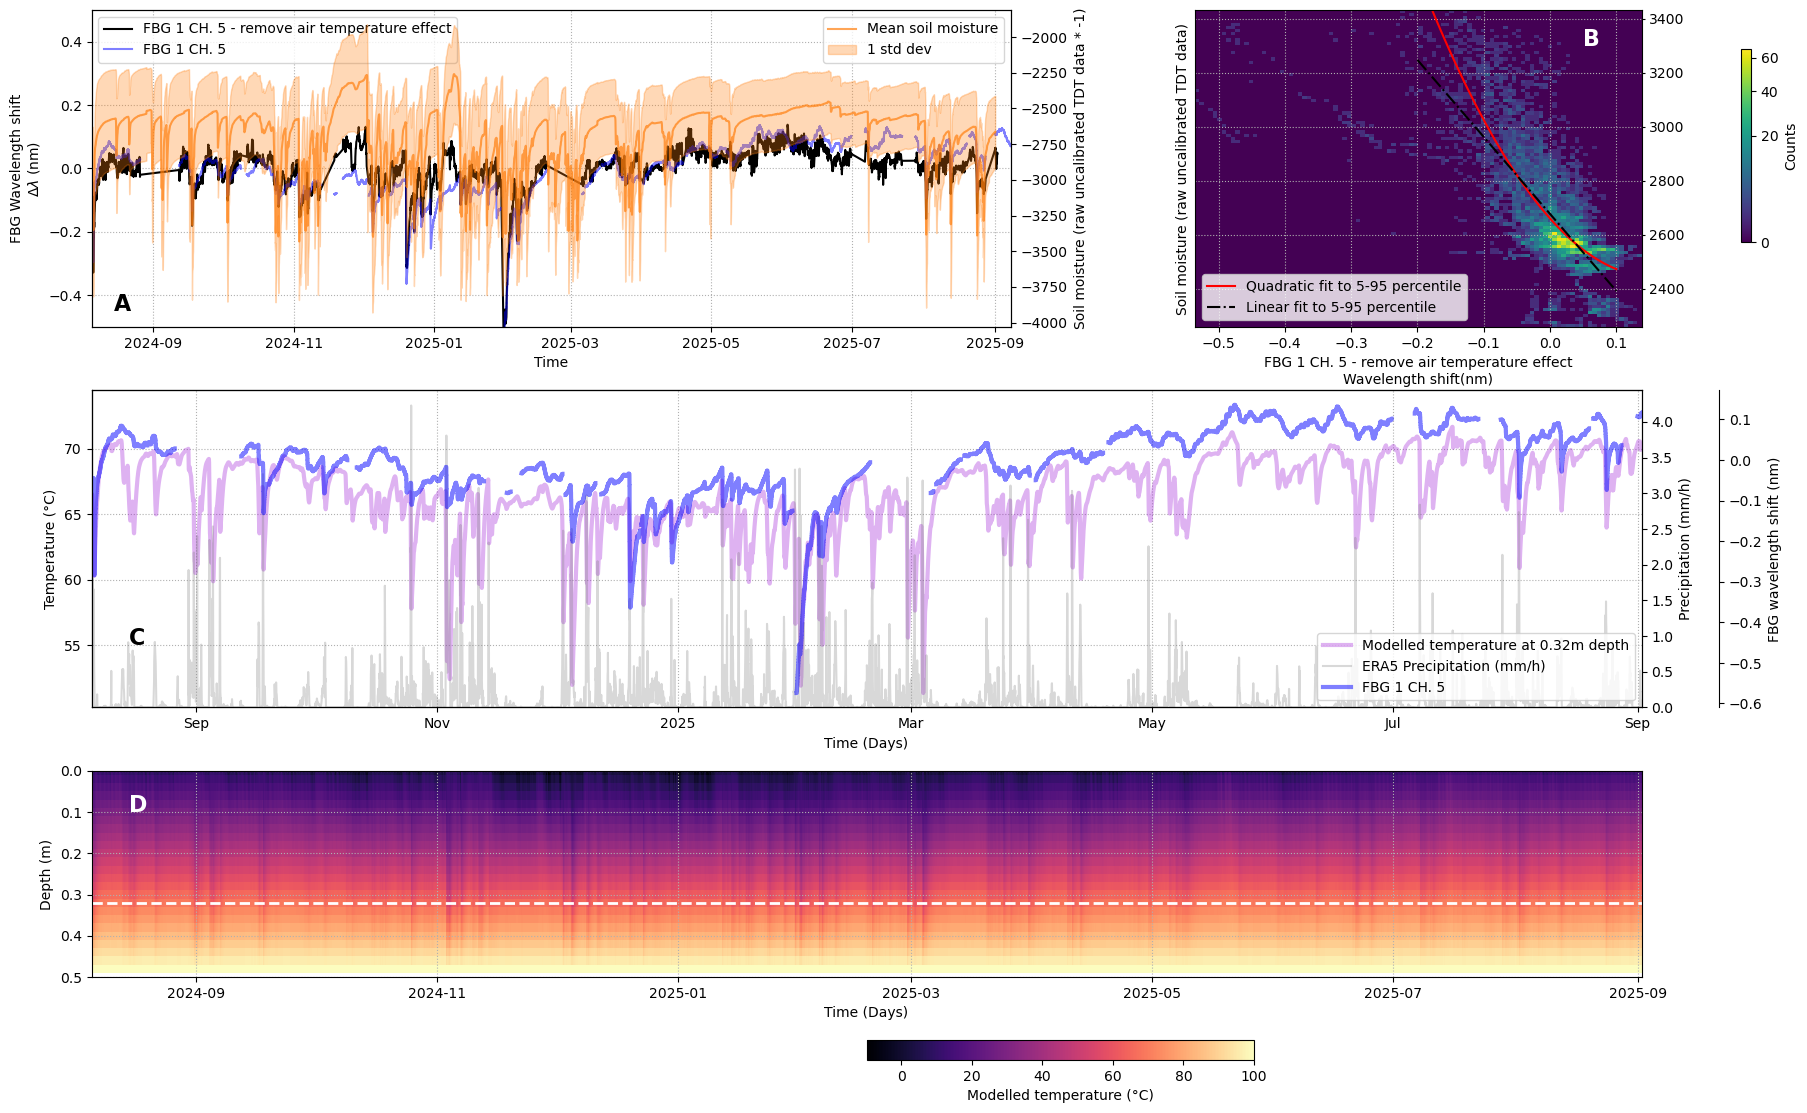

In [46]:
fig = plt.figure(figsize=(25,14))
ax = plt.subplot2grid((3, 10), (0, 0), colspan=6)
ax.plot(geo_temp.sel(Time=common_time_imo).Time.values, (geo_temp_without_air), c='k', zorder=2, label='FBG 1 CH. 5 - remove air temperature effect')
ax.plot(data.Time, data.sel(FBG=0), alpha=0.5, color='b',zorder=2, label='FBG 1 CH. 5')
ax.legend(loc='upper left')
ax.set_ylim(-0.5,0.5)

axb=ax.twinx()
#axt = ax.twinx()
#axt.tick_params(axis='y', left=True, right=False, labelright=False, labelleft=True,length=2)
#axt.set_ylim(-50,50)
#axt.spines['left'].set_position(('outward', 40))
#axt.set_ylabel('$\Delta T$ (°C)')
#axt.plot(geo_temp.sel(Time=common_time_imo).Time.values, (geo_temp_without_air)*1000/10, c='r', zorder=2,)
axb.plot(rng, mean_soil_moisture, label='Mean soil moisture', c='C1', zorder=1, alpha=0.7)
axb.fill_between(rng, mean_soil_moisture - std_soil_moisture, mean_soil_moisture + std_soil_moisture, color='C1', alpha=0.3, label='1 std dev')
#axb.plot(rng, median_soil_moisture, label='Median soil moisture', c='C1', zorder=1,alpha=0.7)
axb.set_ylabel('Soil moisture (raw uncalibrated TDT data * -1)')
axb.legend(loc='upper right')
ax.set_xlim(geo_temp.Time[0], geo_temp.Time[-1])
ax.set_xlabel('Time')
#ax.set_ylabel('Absolute FBG wavelength deviation\nremove air temperature effect (nm)')
ax.set_ylabel('FBG Wavelength shift\n$\Delta \lambda$ (nm)')
ax.grid(ls=':')
#ax.text(np.datetime64('2024-08-15'), -.45, 'A', fontsize=16, fontweight='bold')
ax2 = plt.subplot2grid((3, 10), (0, 7), colspan=3)

ax2.hist2d(xtrain_raw, ytrain_raw, bins=100, norm=PowerNorm(0.5))
ax2.plot(x_quad, a*x_quad**2 + b*x_quad + c, color='r', label='Quadratic fit to 5-95 percentile')
ax2.tick_params(axis='y', left=False, right=True, labelright=True, labelleft=False,length=2)
ax2.plot(x, m*x + p, color='k', ls='-.', label='Linear fit to 5-95 percentile')
ax2.set_xlabel('FBG 1 CH. 5 - remove air temperature effect\nWavelength shift(nm)')
ax2.set_ylabel('Soil moisture (raw uncalibrated TDT data)')
#fig.colorbar(ax2.collections[0], ax=[ax,ax2], label='Counts', orientation='vertical')
ax2.grid(ls=':')
ax2.legend()
#ax2.text(.05, 3300, 'B', fontsize=16, fontweight='bold', c='w')

ax3 = plt.subplot2grid((3, 10), (1, 0), colspan=10)
ax3.plot(time, Temp[:, int(depth/dz)], c='darkviolet', lw=3,alpha=0.3, label='Temperature at 0.4m depth')
ax3.set_xlabel('Time (Days)')
ax3.set_ylabel('Temperature (°C)')
ax3b = ax3.twinx()
ax3b.plot(ds_era5_precip.Time, ds_era5_precip.ERA5_precip, color='grey', alpha=0.3, label='ERA5 Precipitation (mm/h)')
ax3b.set_ylabel('Precipitation (mm/h)')
ax3b.set_ylim(bottom=0)
ax3.grid(ls=':')
ax3c = ax3.twinx()
resampled_geo_temp = geo_temp.reindex(Time=np.arange(geo_temp.Time.values[0], geo_temp.Time.values[-1],1, dtype='datetime64[m]'), 
                                      method='nearest', tolerance=pd.Timedelta('30min'))
resampled_geo_temp.plot(ax=ax3c, alpha=0.5, color='b',zorder=2, lw=3, label='FBG 1 CH. 5',)
ax3c.set_ylabel('FBG wavelength shift (nm)')
ax3c.legend(handles=[ax3.get_lines()[0], ax3b.get_lines()[0], ax3c.get_lines()[0]], 
            labels=['Modelled temperature at %.2fm depth' % depth, 'ERA5 Precipitation (mm/h)', 'FBG 1 CH. 5'], loc='lower right')
ax3c.spines['right'].set_position(('axes', 1.05))

ax4 = plt.subplot2grid((3, 10), (2, 0), colspan=10)
ax4.pcolormesh(time, z, Temp.T, shading='auto', cmap='magma')
#ax4.set_title('Modelled temperature evolution in soil due to precipitation cooling')
ax4.invert_yaxis()
ax4.set_ylim(.5,0)
ax4.set_xlabel('Time (Days)')
ax4.set_ylabel('Depth (m)')
ax4.grid(ls=':')
ax3.set_xlim(geo_temp.Time[0],time[-1])
ax4.set_xlim(geo_temp.Time[0],time[-1])
ax4.axhline(y=depth, color='white', linestyle='--', linewidth=2)

#ax4.text(time[10], .45, 'C', fontsize=16, fontweight='bold', c='w')
fig.colorbar(ax4.collections[0], label='Modelled temperature (°C)', ax=[ax4] , orientation='horizontal', pad=0.2, shrink=0.2)
fig.colorbar(ax2.collections[0], ax=[ax,ax2, ax3, ax4], label='Counts', orientation='vertical', pad=0.05, shrink=0.2, anchor=(0.01, 0.95))

ax.text(np.datetime64('2024-08-15'), -.45, 'A', fontsize=16, fontweight='bold')
ax2.text(.05, 3300, 'B', fontsize=16, fontweight='bold', c='w')
ax3.text(np.datetime64('2024-08-15'), 55, 'C', fontsize=16, fontweight='bold')
ax4.text(np.datetime64('2024-08-15'), .1, 'D', fontsize=16, fontweight='bold', c='w')

plt.savefig(plot_path+'/precipitation_cooling.png', dpi=300, bbox_inches='tight')
plt.show()

## Comparison with TOMST temperature

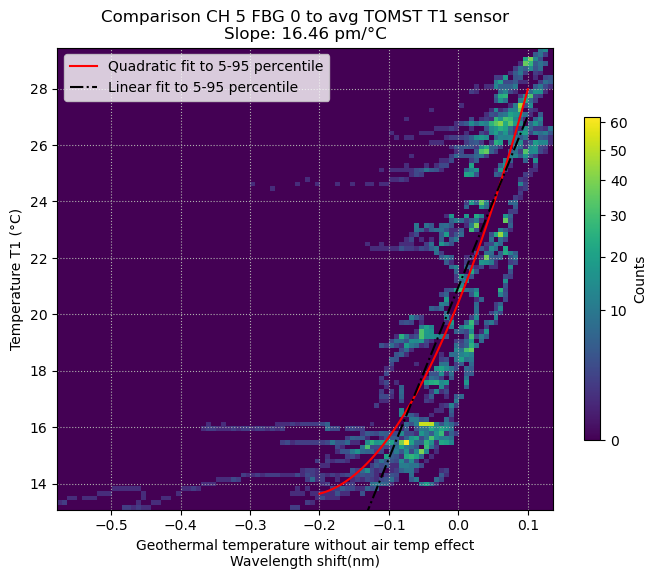

Slope: 16.4609 pm/°C


In [ ]:
plt.figure(figsize=(8,6))
#plt.hist2d(geo_temp_resampled.values[~np.isnan(geo_temp_resampled.values)], -mean_soil_moisture[~np.isnan(geo_temp_resampled.values)], bins=100)
#plt.scatter(geo_temp_resampled.values, -mean_soil_moisture, s=1, alpha=0.5)

geo_temp_resampled = data.sel(FBG=0).reindex(Time=rng, method='nearest', tolerance=pd.Timedelta('30min'))

xtrain_raw = geo_temp_resampled.values[~np.isnan(geo_temp_resampled.values)]
xtrain = xtrain_raw[(np.percentile(xtrain_raw, 5) < xtrain_raw) & (xtrain_raw < np.percentile(xtrain_raw, 95))]
ytrain_raw = mean_T1[~np.isnan(geo_temp_resampled.values)]
ytrain = ytrain_raw[(np.percentile(xtrain_raw, 5) < xtrain_raw) & (xtrain_raw < np.percentile(xtrain_raw, 95))]

plt.hist2d(xtrain_raw, ytrain_raw, bins=100, norm=PowerNorm(0.5))

m, p = np.polyfit(xtrain,ytrain, 1)
x = np.linspace(-.2, .1, 100)

a,b,c = np.polyfit(xtrain, ytrain, 2)
x_quad = np.linspace(-.2, .1, 100)
plt.plot(x_quad, a*x_quad**2 + b*x_quad + c, color='r', label='Quadratic fit to 5-95 percentile')

plt.plot(x, m*x + p, color='k', ls='-.', label='Linear fit to 5-95 percentile')
plt.xlabel('Geothermal temperature without air temp effect\nWavelength shift(nm)')
plt.ylabel('Temperature T1 (°C)')
plt.colorbar(label='Counts', shrink=0.7)
plt.grid(ls=':')
plt.legend()
plt.title(f'Comparison CH 5 FBG 0 to avg TOMST T1 sensor\nSlope: {1/m*1000:.2f} pm/°C')
plt.show()
print(f'Slope: {1/m*1000:.4f} pm/°C')